# Fire Detection Model Training with MobileNetV2

This notebook trains a MobileNetV2 model to detect fire in thermal images. It includes data loading, model training, evaluation (Accuracy, Precision, Recall, F1 Score, Confusion Matrix), and post-training quantization.

In [28]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from pathlib import Path
import json

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


In [29]:
# Configuration
BATCH_SIZE = 32
IMG_SIZE = (120, 160)
DATA_DIR = Path("../data") # Relative to notebook location
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load Datasets
# Ensure you have 'fire' and 'nofire' subdirectories in DATA_DIR
try:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.2,
        subset="training",
        seed=123,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_names=['fire', 'nofire']
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.2,
        subset="validation",
        seed=123,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_names=['fire', 'nofire']
    )

    class_names = train_ds.class_names
    print(f"Class names: {class_names}")

    # Configure dataset for performance
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
    
except FileNotFoundError:
    print(f"Error: Data directory '{DATA_DIR}' not found or empty. Please populate it with 'fire' and 'nofire' folders.")
except Exception as e:
    print(f"Error loading dataset: {e}")

Found 452 files belonging to 2 classes.
Using 362 files for training.
Found 452 files belonging to 2 classes.
Using 90 files for validation.
Class names: ['fire', 'nofire']


In [30]:
# Data Augmentation
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])

# Create the base model from the pre-trained model MobileNet V2
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                              alpha=0.75,
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False # Freeze base model

# Create new model on top
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
prediction_layer = tf.keras.layers.Dense(1 if len(class_names) == 2 else len(class_names), 
                                activation='sigmoid' if len(class_names) == 2 else 'softmax')
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy() if len(class_names) == 2 else tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])
model.summary()

/tmp/ipykernel_7231/2571570942.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 120, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 120, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_3 (TrueDivide)      │ (None, 120, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_3 (Subtract)           │ (None, 120, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_0.75_224            │ (None, 4, 5, 1280)     │     1,382,064 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,383,345 (5.28 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 1,382,064 (5.27 MB)

In [31]:
# Conteo de tus datos
import os
n_fire = len(os.listdir(DATA_DIR / "fire"))
n_nofire = len(os.listdir(DATA_DIR / "nofire"))
total = n_fire + n_nofire

# Cálculo de pesos (Inversa de la frecuencia)
# Queremos que la suma de (peso * cantidad) sea equilibrada
weight_for_fire = (1 / n_fire) * (total / 2.0)
weight_for_nofire = (1 / n_nofire) * (total / 2.0)

class_weight = {0: weight_for_fire, 1: weight_for_nofire}
print(f"Pesos asignados: {class_weight}")

epochs = 15 
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Pesos asignados: {0: 0.9535864978902953, 1: 1.0511627906976744}
Epoch 1/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 295ms/step - accuracy: 0.5635 - loss: 0.7613 - val_accuracy: 0.6000 - val_loss: 0.6832
Epoch 2/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 195ms/step - accuracy: 0.6160 - loss: 0.6756 - val_accuracy: 0.6111 - val_loss: 0.6470
Epoch 3/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 251ms/step - accuracy: 0.6381 - loss: 0.6425 - val_accuracy: 0.6444 - val_loss: 0.6162
Epoch 4/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step - accuracy: 0.6547 - loss: 0.6453 - val_accuracy: 0.7000 - val_loss: 0.5838
Epoch 5/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.7403 - loss: 0.5566 - val_accuracy: 0.7222 - val_loss: 0.5540
Epoch 6/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.7155 - loss: 0.5442 - val_accuracy: 0.7333 - val_loss: 0.5303
Epoch 7/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 214ms/step - accuracy: 0.7486 - loss: 0.5190 - val_accuracy: 0.7556 - val_loss: 0.5087
Epoch 8/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s

In [32]:
base_model.trainable = True


fine_tune_lr = 1e-5 

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=fine_tune_lr),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)


history_fine = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=10,  # 10 extra epochs of fine-tuning
  class_weight=class_weight
)

Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 25s 846ms/step - accuracy: 0.5994 - loss: 0.7074 - val_accuracy: 0.8889 - val_loss: 0.3808
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 691ms/step - accuracy: 0.6464 - loss: 0.6343 - val_accuracy: 0.8889 - val_loss: 0.3717
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 900ms/step - accuracy: 0.6768 - loss: 0.6012 - val_accuracy: 0.9000 - val_loss: 0.3664
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 777ms/step - accuracy: 0.6989 - loss: 0.5569 - val_accuracy: 0.9000 - val_loss: 0.3613
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 775ms/step - accuracy: 0.7597 - loss: 0.4994 - val_accuracy: 0.9000 - val_loss: 0.3572
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 775ms/step - accuracy: 0.7486 - loss: 0.4843 - val_accuracy: 0.9000 - val_loss: 0.3547
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 783ms/step - accuracy: 0.8287 - loss: 0.4004 - val_accuracy: 0.8889 - val_loss: 0.3525
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 707ms/step - accuracy: 0.8177 - loss: 0.4130 - val_accuracy: 

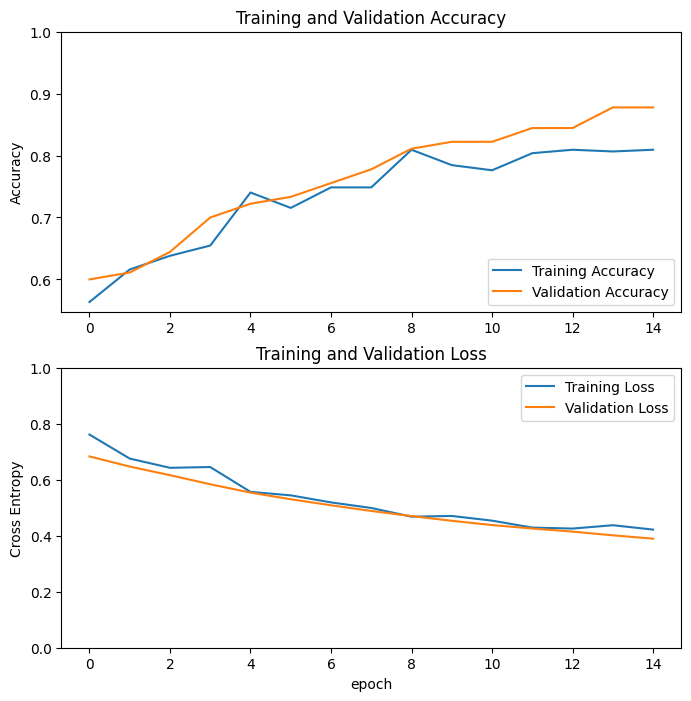

In [33]:
# Plot Training History
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.8778 - loss: 0.3494
Test Loss: 0.34938758611679077
Test Accuracy: 0.8777777552604675
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 802ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 770ms/step

Classification Report:
              precision    recall  f1-score   support

        fire       0.93      0.89      0.91        46
      nofire       0.89      0.93      0.91        44

    accuracy                           0.91        90
   macro avg       0.91      0.91      0.91        90
weighted avg       0.91      0.91      0.91        90



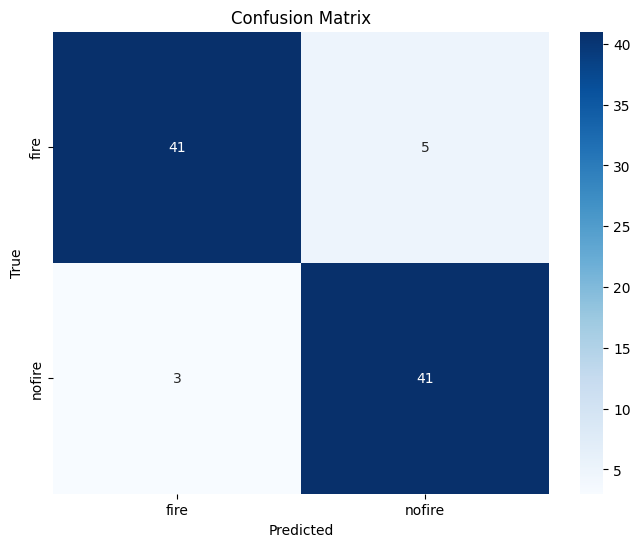

In [34]:
# Evaluate on validation set
loss, accuracy = model.evaluate(val_ds)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

# Get predictions
y_true = []
y_pred = []

threshold = 0.3 # original = 0.5

for images, labels in val_ds:
    predictions = model.predict(images)
    if len(class_names) == 2:
        y_pred.extend((predictions > threshold).astype(int).flatten())
    else:
        y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification Report (Precision, Recall, F1)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [35]:
print("Saving and Quantizing Model")
print("=" * 50)

# Save original model
model_path = MODELS_DIR / "mobilenetv2_classifier.keras"
model.save(str(model_path))
original_size = os.path.getsize(model_path) / (1024 * 1024)  # Convert to MB
print(f"✓ Original model saved: {model_path}")
print(f"  Size: {original_size:.2f} MB")

# Convert to TensorFlow Lite with full integer quantization (int8)

def representative_dataset():
    """
    Representative dataset for full integer quantization.
    Important:
    - The model already includes MobileNetV2 preprocess_input() internally.
    - Therefore, calibration samples must be raw images in [0,255] as float32,
      not manually normalized to [-1,1].
    """
    for images, _ in train_ds.unbatch().batch(1).take(300):
        yield [tf.cast(images, tf.float32)]

# Convert the tflite.
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter._experimental_disable_per_channel_quantization_for_dense_layers = True
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

try:
    tflite_quant_model = converter.convert()

    # Save the quantized model.
    quantized_model_path = MODELS_DIR / "mobilenetv2_classifier_quantized_int8_2.tflite"
    with open(quantized_model_path, 'wb') as f:
        f.write(tflite_quant_model)

    quantized_size = os.path.getsize(quantized_model_path) / (1024 * 1024)
    print(f"✓ Quantized model saved: {quantized_model_path}")
    print(f"  Quantization: int8 (full integer)")
    print(f"  Size: {quantized_size:.2f} MB")

    # Calculate compression ratio
    compression_ratio = (1 - quantized_size / original_size) * 100
    print(f"\nModel Compression Summary:")
    print(f"  Original size: {original_size:.2f} MB")
    print(f"  Quantized size: {quantized_size:.2f} MB")
    print(f"  Compression: {compression_ratio:.1f}%")
    print(f"  Size reduction: {original_size - quantized_size:.2f} MB")

except Exception as e:
    print(f"Error during quantization: {e}")

# Save class mapping
classes_path = MODELS_DIR / "classes.json"
with open(classes_path, 'w') as f:
    json.dump(class_names, f, indent=2)
print(f"\n✓ Class mapping saved: {classes_path}")

print("\nModel training and quantization complete!")
print(f"All models saved in: {MODELS_DIR}")

Saving and Quantizing Model
✓ Original model saved: ../models/mobilenetv2_classifier.keras
  Size: 16.31 MB
INFO:tensorflow:Assets written to: /tmp/tmph7mekiwu/assets


INFO:tensorflow:Assets written to: /tmp/tmph7mekiwu/assets


Saved artifact at '/tmp/tmph7mekiwu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 120, 160, 3), dtype=tf.float32, name='keras_tensor_649')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  134545498355280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134543965583696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134543965584656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134543965584080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134543965583312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134543965584464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134540343194064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134540343196752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134543965582928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134540343192912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1345403431

/home/osvaldo/Documents/IA+EO/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1773616248.745698    7231 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1773616248.745725    7231 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-03-15 19:10:48.745885: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmph7mekiwu
2026-03-15 19:10:48.752860: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-03-15 19:10:48.752875: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmph7mekiwu
2026-03-15 19:10:48.852359: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-03-15 19:10:49.424957: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at pat

✓ Quantized model saved: ../models/mobilenetv2_classifier_quantized_int8_2.tflite
  Quantization: int8 (full integer)
  Size: 1.67 MB

Model Compression Summary:
  Original size: 16.31 MB
  Quantized size: 1.67 MB
  Compression: 89.8%
  Size reduction: 14.64 MB

✓ Class mapping saved: ../models/classes.json

Model training and quantization complete!
All models saved in: ../models


In [ ]:
# Load and test the Quantized TFLite model on sample images
import numpy as np
import matplotlib.pyplot as plt

# Load the TFLite model and allocate tensors
interpreter = tf.lite.Interpreter(model_path=str(quantized_model_path))
interpreter.allocate_tensors()

# Get input and output tensors
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"Input Type: {input_details[0]['dtype']}")
print(f"Output Type: {output_details[0]['dtype']}")

# Get quantization parameters
input_scale, input_zero_point = input_details[0]['quantization']
output_scale, output_zero_point = output_details[0]['quantization']

def evaluate_tflite_model(dataset, num_samples=10):
    correct = 0
    tested = 0
    
    plt.figure(figsize=(15, 6))
    
    # Take randomly some samples from the validation set
    for images, labels in dataset.unbatch().shuffle(100).take(num_samples):
        # 1. Get original image and true label
        img = images.numpy()
        true_label = labels.numpy()
        
        # 2. Preprocess specifically for INT8 quantization
        # The model expects int8 ranging from -128 to 127
        input_data = img / input_scale + input_zero_point
        input_data = np.clip(input_data, -128, 127).astype(np.int8)
        input_data = np.expand_dims(input_data, axis=0) # Add batch dimension
        
        # 3. Run inference
        interpreter.set_tensor(input_details[0]['index'], input_data)
        interpreter.invoke()
        
        # 4. Get output and dequantize it back to float32
        output_data = interpreter.get_tensor(output_details[0]['index'])[0]
        prediction_float = (output_data.astype(np.float32) - output_zero_point) * output_scale
        
        if len(class_names) == 2:
            pred_class = 1 if prediction_float[0] > 0.5 else 0
            confidence = prediction_float[0] if pred_class == 1 else 1 - prediction_float[0]
        else:
            pred_class = np.argmax(prediction_float)
            confidence = prediction_float[pred_class]
            
        if pred_class == true_label:
            correct += 1
        tested += 1
        
        # Plotting the images with results
        plt.subplot(2, num_samples//2, tested)
        plt.imshow(img.astype(np.uint8))
        plt.title(f"True: {class_names[true_label]}\nPred: {class_names[pred_class]}\nConf: {confidence:.2f}")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()
    
    print(f"\nAccuracy on TFLite subset ({num_samples} images): {correct/tested:.2%}")

# Run the evaluation on validation dataset
evaluate_tflite_model(val_ds, num_samples=10)
